In [1]:
#Purpose: Imports all required PyTorch, Torchvision, and utility libraries, and checks if a GPU is available to accelerate training.

from torchvision import datasets #imports dataset utilities to load data
import torchvision.transforms as transforms #imports image augmentation tools

from torch.utils.data import Dataset, DataLoader #imports tools for handling dataset and creating batches
import torch #imports pytorch library
import torch.nn as nn #imports pytorch's neural network module

import numpy as np #imports numpy for numerical operations
import matplotlib.pyplot as plt #imports matplot for plotting graphs
#jupyter command to plot matplot plottings inside the notebook
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu" #checks if nvidia gpu is present or not
print(device)

cpu


In [2]:
#Purpose:Automatically downloads the dataset using KaggleHub

import kagglehub # Imports kagglehub to fetch datasets directly from Kaggle
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset") #downloads the MRI dataset & return its storage path
print("Path to dataset files:", path) #directory path where the datasets are stored

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [3]:
#Splits dataset into training, validation, and test subsets.

import os
import torchvision.transforms as transforms # Re-ensures transform tools are imported
from torch.utils.data import random_split   # Imports random_split to divide a dataset into separate subsets

size = 64 #target img resolution
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    transforms.RandomRotation(15),        # rotate +/-15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                # convert PIL -> float tensor [0.0,1.0]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)), #resizes input images to 64x64 pixel
    transforms.ToTensor()            # converts PIL images to pytorch tensor
])

# The Kaggle dataset directories are usually 'Training' and 'Testing'
train_folder = os.path.join(path, 'Training')
test_folder = os.path.join(path, 'Testing')

train_data = datasets.ImageFolder(train_folder, transform = train_transform) # Loads training images with augmentations
val_test_data = datasets.ImageFolder(test_folder,transform = val_transform)  # Loads test/validation images with base transform

# Split original test dataset into validation (50%) and test (50%)
val_size = len(val_test_data) // 2
test_size = len(val_test_data) - val_size

val_data, test_data = random_split(
    val_test_data,
    [val_size, test_size]
)

In [4]:
#Purpose:Inspects split sizes and sets up core training variables.

print('Dataset Summary') # Prints section header
print('Train Data: ', len(train_data)) # Prints total number of training samples
print('Validation Data: ', len(val_data)) # Prints total number of validation samples
print('Test Data: ', len(test_data))  # Prints total number of test samples
print('Classess and Indices: ' , train_data.class_to_idx) # Prints class labels mapped to numeric indices

batch_size = 32 # Sets number of samples processed per gradient update step
learning_rate=1e-3 # Sets the step size for weight updates using the optimizer
epoch_number = 10  # Sets total complete passes over the training dataset

trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2) # Creates training DataLoader (shuffles data)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)  # Creates validation DataLoader (no shuffling)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2) # Creates test DataLoader (no shuffling)

Dataset Summary
Train Data:  5600
Validation Data:  800
Test Data:  800
Classess and Indices:  {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [5]:
#Purpose:Defines the custom Convolutional Neural Network structure, loss function, and optimizer.

from torch.optim import SGD, Adam # Imports SGD and Adam optimization algorithms
def get_model(): #constructs CNN & Defines a function to instantiate and return the model, loss, and optimizer
    model = nn.Sequential(   ## Defines a sequential container for neural network layers
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3), #RGB input channels, outputs 64 feature maps, 3x3 filter
        nn.ReLU(), #Activation Fn: Introduces non-linearity
        nn.MaxPool2d(2), # Max pooling layer: Downsamples spatial dimensions by a factor of 2
        nn.Conv2d(64, 128, kernel_size=3), # Conv layer 2: Takes 64 channels, outputs 128 feature maps, 3x3 filter
        nn.ReLU(), # Activation function: Introduces non-linearity
        nn.MaxPool2d(2), # Max pooling layer: Downsamples spatial dimensions by a factor of 2

        #Classifier the brain of the network
        nn.Flatten(), # Flattens 2D feature maps into a 1D vector for the linear layers
        nn.Linear(128*14*14, 256), # Fully connected hidden layer: maps flattened features to 256 nodes
        nn.ReLU(),
        nn.Linear(256, 4) # Output layer: maps 256 nodes to 4 class logits
    ).to(device) #moves entire workload to the chosen cloud hardware

    loss_fn = nn.CrossEntropyLoss() # Defines Cross-Entropy Loss for multi-class/binary classification
    optimizer = Adam(model.parameters(), lr=learning_rate) # Defines Adam optimizer to adjust model parameters
    return model, loss_fn, optimizer # Returns the compiled model, loss function, and optimizer instance

In [6]:
#Purpose:Implements functions to train the model for one epoch and evaluate it without computing gradients.

def train_one_epoch(data_loader, model, loss_fn, optimizer): #defines func for a single training epoch
    model.train() #sets the model to training mode
    epoch_losses, epoch_accuracies = [], [] # Initializes lists to track batch losses and accuracies
    for x, y in data_loader: # Loops through batches of images (x) and labels (y) from loader
        x, y = x.to(device), y.to(device) # Moves image tensors and target labels to the active hardware device

        optimizer.zero_grad() # Clears old gradients from the previous optimization step
        prediction = model(x) # Forward pass: passes input images through the CNN to get predictions
        batch_loss = loss_fn(prediction, y) # Computes error/loss between predictions and true labels via CrossEntropy
        batch_loss.backward() # Backward pass: computes gradients via backpropagation
        optimizer.step() # Updates model weights using the calculated gradients

        epoch_losses.append(batch_loss.item()) # Appends current batch loss value to tracking list
        is_correct = (prediction.argmax(-1) == y).tolist() # Checks if predicted class index matches ground truth label
        epoch_accuracies.extend(is_correct) # Extends accuracy list with batch results
    return np.mean(epoch_losses), np.mean(epoch_accuracies) # Returns average epoch loss and accuracy

@torch.no_grad() # Decorator to disable gradient tracking during evaluation to save memory
def validation(data_loader, model, loss_fn): # Defines function for evaluating model performance
    model.eval() #sets model to evaluation mode
    val_losses, val_accuracies = [], []
    for x, y in data_loader:            # Loops through validation/test data batches
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x) # Forward pass: generates predictions without saving gradients
        val_losses.append(loss_fn(prediction, y).item()) # Appends batch validation loss
        is_correct = (prediction.argmax(-1) == y).tolist() # Checks prediction correctness
        val_accuracies.extend(is_correct)                  # Extends accuracy list
    return np.mean(val_losses), np.mean(val_accuracies)    # Returns average validation loss and accuracy

In [7]:
#Purpose:Prints architecture specifications, runs the training loop across all epochs, saves weights, and plots performance metrics.
from torchsummary import summary  # Imports summary tool to display detailed layer shapes and params
model, loss_fn, optimizer = get_model() # Initializes model, loss function, and optimizer
summary(model, input_size=(3,64,64));  # Prints layer-by-layer architectural summary for input size 3x32x32

## Training Loop ###
train_losses, train_accuracies = [], [] # Initializes history list for training metrics
val_losses, val_accuracies = [], []     # Initializes history list for validation metrics

for epoch in range(epoch_number):  # Outer loop iterating through each training epoch
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer) # Trains for 1 epoch
  train_losses.append(epoch_loss) # Saves training loss value
  train_accuracies.append(epoch_accuracy) # Saves training accuracy value

  v_loss, v_acc =  validation(val_dl,model,loss_fn) # Evaluates model on validation data loader
  val_losses.append(v_loss) # Saves validation loss value
  val_accuracies.append(v_acc) # Saves validation accuracy value

  print(f"Epoch [{epoch + 1}/{epoch_number}]"  # Prints formatted status report for current epoch
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
         MaxPool2d-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
              ReLU-5          [-1, 128, 29, 29]               0
         MaxPool2d-6          [-1, 128, 14, 14]               0
           Flatten-7                [-1, 25088]               0
            Linear-8                  [-1, 256]       6,422,784
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 4]           1,028
Total params: 6,499,460
Trainable params: 6,499,460
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.05
Forward/backward pass size (MB): 6.25
Params size (MB): 24.79
Estima

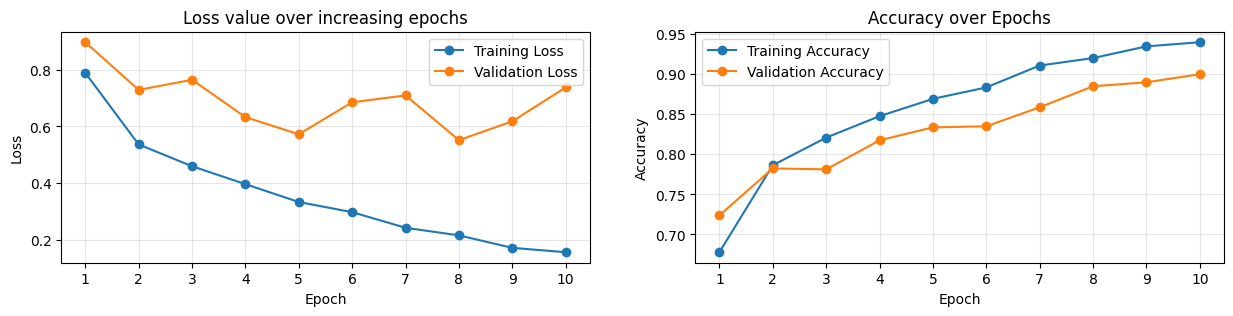

In [8]:
#Purpose: Saves the trained model weights to disk, creates the epoch array, and plots side-by-side training and validation loss/accuracy curves.
torch.save(model.state_dict(), 'CNN_23-53060-3_weights.pth') # Saves trained model parameter weights to disk

epochs = np.arange(epoch_number) + 1 # Creates an array of epoch numbers for the X-axis
plt.figure(figsize=(15, 3))          # Sets dimensions for the figure canvas
plt.subplot(121)                     # Creates subplot 1 for loss curves
plt.title("Loss value over increasing epochs") # Sets title for loss plot
plt.plot(epochs, train_losses, marker='o', label="Training Loss")  # Plots training loss curve
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")  # Plots validation loss curve
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)  # Sets discrete ticks for epochs
plt.legend()
plt.grid(alpha=0.3) #adds subtle background grid

plt.subplot(122)  # Creates subplot 2 for accuracy curves
plt.title("Accuracy over Epochs") # Sets title for accuracy plot
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")  # Plots training accuracy curve
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")  # Plots validation accuracy curve
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)  # Sets discrete ticks for epochs
plt.legend()
plt.grid(alpha=0.3) # Adds subtle background grid
plt.show() # Renders and displays both plots

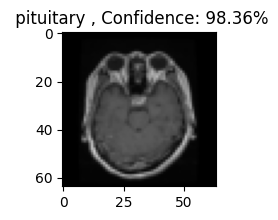

Test Loss : 0.89 , Test Accuracy: 89.00%


In [11]:
# Single Image Test Inference and Final Evaluation Purpose:** Tests an individual image from the test set and evaluates overall test set accuracy.

test_img, label = test_data[44] # Pulls the 45th sample image and label from the test subset
img = test_img.view(-1,3,size,size).to(device) # Reshapes image tensor and sends it to the device

output = model(img) # Passes image through model to generate raw class logits
pred = torch.exp(output)/torch.sum(torch.exp(output)) # Converts logits to probability distribution via Softmax
confidence, index  = pred.max(-1) # Extracts highest probability score and corresponding class index

plt.figure(figsize=(2,2))  # Sets figure size for single image display
plt.imshow(test_img.view(3,size,size).permute(1,2,0)) # Re-orders tensor channels from (C,H,W) to (H,W,C) for plotting
plt.title(f' {train_data.classes[index]} , Confidence: {confidence.item()*100:0.2f}%') # Sets title with predicted class and confidence
plt.show() # Renders the test image output

test_loss, test_acc =  validation(test_dl,model,loss_fn) # Evaluates the trained model across the entire test data loader
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%') # Prints final test metrics